# 托卡马克中带电粒子轨道特征汇报

本汇报围绕带电粒子在托卡马克磁场中的运动展开，包含四个部分：
1. 带电粒子运动方程及其无量纲化；
2. 托卡马克磁力线与极向面投影；
3. 改变粒子速度的 pitch angle，观察 passing 与 trapped 轨道的转变；
4. 改变粒子能量，观察轨道与磁力线的偏移。

最后对轨道特征的物理成因进行解释。

## 1. 模型：带电粒子运动方程无量纲化

带电粒子在电磁场中的运动由洛伦兹力决定：
$$m\frac{d\mathbf{v}}{dt} = q(\mathbf{E} + \mathbf{v} \times \mathbf{B}), \quad \frac{d\mathbf{x}}{dt} = \mathbf{v}$$

为突出物理参数的作用，对方程进行无量纲化。取：
- 长度：$\mathbf{x} = R_0 \tilde{\mathbf{x}}$
- 时间：$t = \Omega_c^{-1} \tilde{t}$，其中 $\Omega_c = qB_0/m$ 为回旋频率
- 速度：$\mathbf{v} = v_0 \tilde{\mathbf{v}}$，$v_0$ 为特征速度
- 磁场：$\mathbf{B} = B_0 \tilde{\mathbf{B}}$，$\mathbf{E} = E_0 \tilde{\mathbf{E}}$

代入得速度方程：
$$\frac{d\tilde{\mathbf{v}}}{d\tilde{t}} = \frac{E_0}{v_0 B_0} \tilde{\mathbf{E}} + \tilde{\mathbf{v}} \times \tilde{\mathbf{B}}$$

位置方程：
$$\frac{d\tilde{\mathbf{x}}}{d\tilde{t}} = \frac{v_0}{\Omega_c R_0} \tilde{\mathbf{v}} = \rho_* \tilde{\mathbf{v}}$$

若 $E_0 = 0$，则速度方程简化为：
$$\frac{d\tilde{\mathbf{v}}}{d\tilde{t}} = \tilde{\mathbf{v}} \times \tilde{\mathbf{B}}$$

关键无量纲参数为：
$$\rho_* = \frac{v_0}{\Omega_c R_0} = \frac{\rho_L}{R_0}$$

即拉莫尔半径与装置大半径之比。$\rho_* \ll 1$ 时导心近似成立，轨道紧贴磁力线；$\rho_*$ 增大时，轨道与磁力线的偏移显著。

**本算例参数**：$v_0 = 1.2\times10^5$ m/s（约 75 eV 质子），$B_0 = 5$ T，$R_0 = 10$ m，计算得 $\rho_L \approx 0.25$ mm，$\rho_* \approx 2.5\times10^{-5}$。这说明导心近似非常好，但也意味着轨道偏移在装置尺度上很小，需要放大才能看清。

**说明**：代码使用 SI 单位实现，与上述无量纲方程等价。

In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'WenQuanYi Micro Hei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

from src.particles import Particle
from src.fields import TokamakField
from src.fieldlines import integrate_fieldline, flux_surface_points
from src.integrators import guiding_center_integrate

PROTON_MASS = 1.6726219e-27
PROTON_CHARGE = 1.6021766e-19

field = TokamakField(B0=5.0, R0=10.0, a=1.0, q0=1.0, q1=2.0)
R0 = 10.0


## 2. 托卡马克磁力线与极向面投影

托卡马克磁力线是绕环向螺旋前进的曲线，由环向场和极向场共同决定。磁力线在三维空间呈螺旋状，在极向面（R-Z 平面）上的投影为闭合曲线。

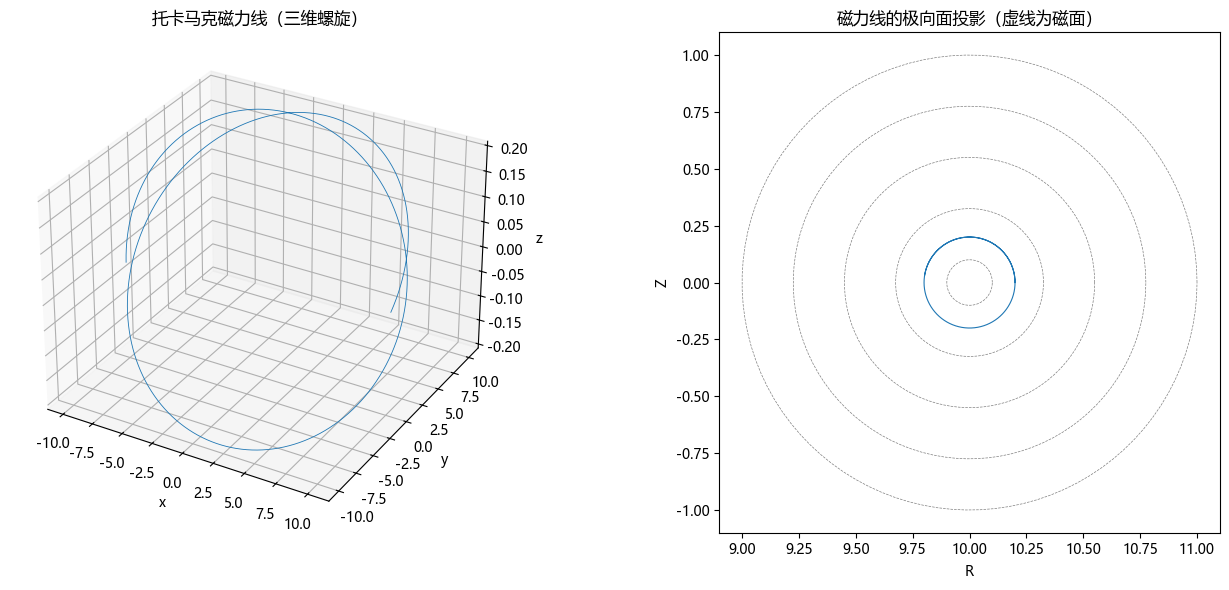

In [2]:
# 积分一条磁力线
x0 = np.array([10.2, 0.0, 0.0])
ds = 1e-3
n_steps = 100000
traj = integrate_fieldline(field, x0, ds, n_steps)

# 画三维磁力线与极向面投影
fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.plot(traj[:, 0], traj[:, 1], traj[:, 2], lw=0.6)
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('z')
ax1.set_title('托卡马克磁力线（三维螺旋）')

ax2 = fig.add_subplot(1, 2, 2)
R = np.sqrt(traj[:, 0]**2 + traj[:, 1]**2)
ax2.plot(R, traj[:, 2], lw=0.8)
# 叠加磁面
for Rs, Zs, r in flux_surface_points(R0, 1.0, n_r=5):
    ax2.plot(Rs, Zs, 'k--', lw=0.5, alpha=0.5)
ax2.set_xlabel('R')
ax2.set_ylabel('Z')
ax2.set_title('磁力线的极向面投影（虚线为磁面）')
ax2.set_aspect('equal')

plt.tight_layout()
plt.show()

## 3. 改变 pitch angle：passing 与 trapped 轨道

固定粒子总速度，改变平行速度占比 $v_\parallel/v$（即改变 pitch angle），可以观察到粒子从通行（passing）到捕获（trapped）的转变。

- **passing**：$v_\parallel/v$ 较大，粒子沿磁力线持续前进，形成通行轨道。
- **trapped**：$v_\parallel/v$ 较小，粒子被磁镜效应捕获，形成香蕉轨道。

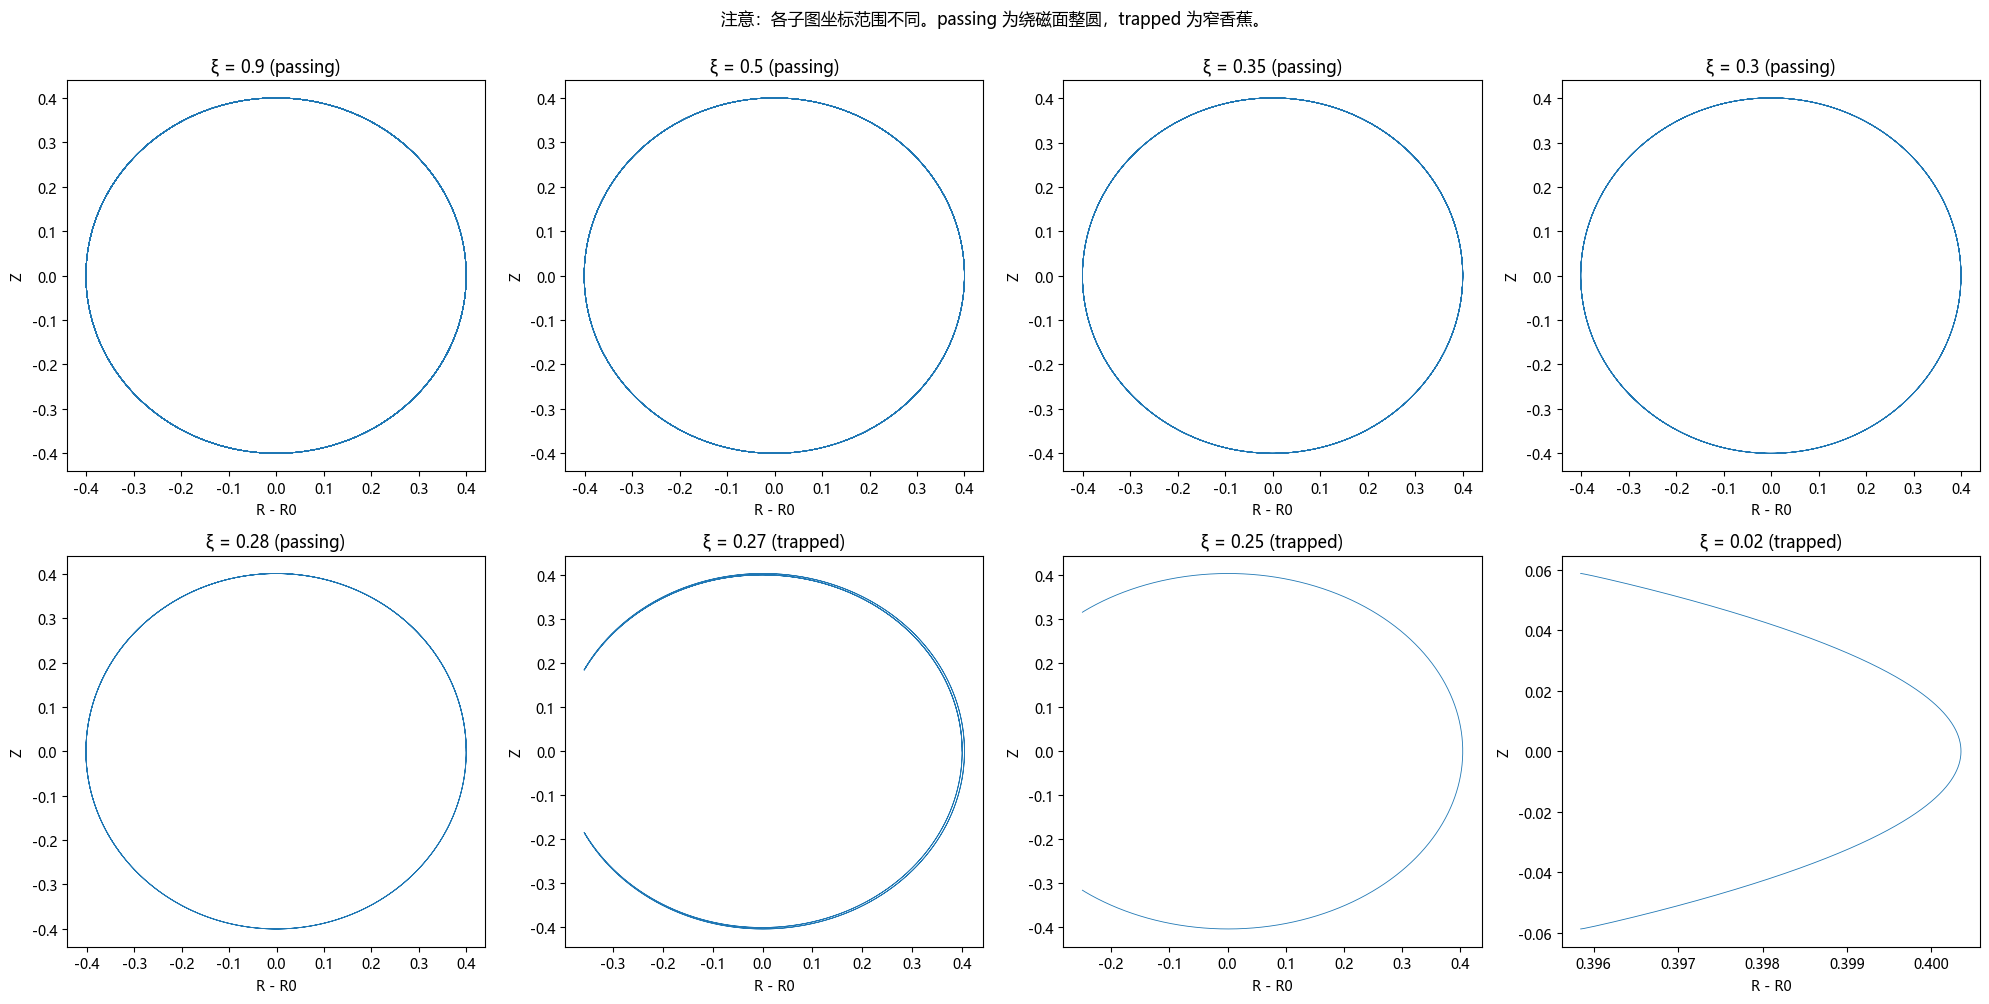

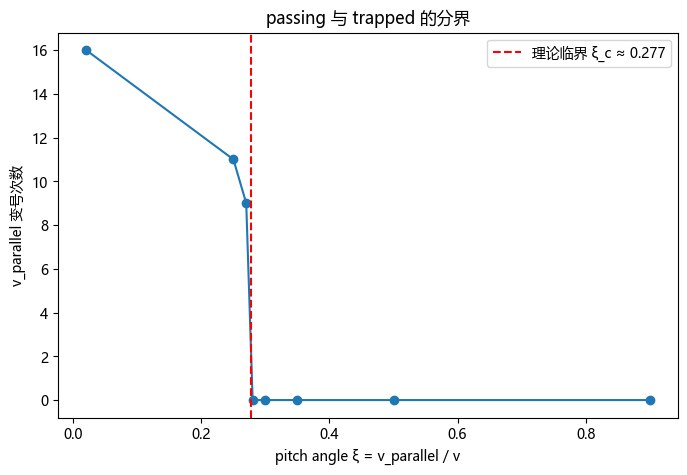

In [3]:
# 固定总速度，改变 v_parallel/v，加密到捕获分界附近
v_total = 1.2e5
pitch_ratios = [0.9, 0.5, 0.35, 0.30, 0.28, 0.27, 0.25, 0.02]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
sign_counts = []
for ax, ratio in zip(axes.flat, pitch_ratios):
    v_para = ratio * v_total
    v_perp = np.sqrt(v_total**2 - v_para**2)
    v = np.array([v_perp, v_para, 0.0])
    p = Particle(PROTON_CHARGE, PROTON_MASS, np.array([10.4, 0.0, 0.0]), v)
    result = guiding_center_integrate(field, p, dt=1e-7, n_steps=400000)

    vparas = result['v_parallel']
    sign_changes = np.where(np.diff(np.sign(vparas)) != 0)[0]
    sign_counts.append(len(sign_changes))
    # 对 trapped 粒子只画一个完整 bounce，使香蕉形状清晰可见
    if len(sign_changes) >= 2 and ratio < 0.27:
        start, end = sign_changes[0], sign_changes[1]
        R = np.sqrt(result['trajectory'][start:end, 0]**2 + result['trajectory'][start:end, 1]**2)
        Z = result['trajectory'][start:end, 2]
    else:
        R = np.sqrt(result['trajectory'][:200000, 0]**2 + result['trajectory'][:200000, 1]**2)
        Z = result['trajectory'][:200000, 2]

    ax.plot(R - R0, Z, lw=0.6)
    ax.set_xlabel('R - R0')
    ax.set_ylabel('Z')
    kind = 'trapped' if len(sign_changes) >= 2 else 'passing'
    ax.set_title(f'ξ = {ratio} ({kind})')

fig.suptitle('注意：各子图坐标范围不同。passing 为绕磁面整圆，trapped 为窄香蕉。', y=1.0)
plt.tight_layout()
plt.show()

# 附加：v_parallel 变号次数随 pitch angle 的变化
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pitch_ratios, sign_counts, 'o-')
ax.axvline(x=0.277, color='r', linestyle='--', label='理论临界 ξ_c ≈ 0.277')
ax.set_xlabel('pitch angle ξ = v_parallel / v')
ax.set_ylabel('v_parallel 变号次数')
ax.set_title('passing 与 trapped 的分界')
ax.legend()
plt.show()

## 4. 改变粒子能量：轨道与磁力线的偏移

固定 pitch angle，改变粒子能量。能量越高，拉莫尔半径越大，导心轨道与磁力线的偏移越明显。

这里用同一条磁力线作为参考，比较不同能量下导心轨道与磁力线的偏离。

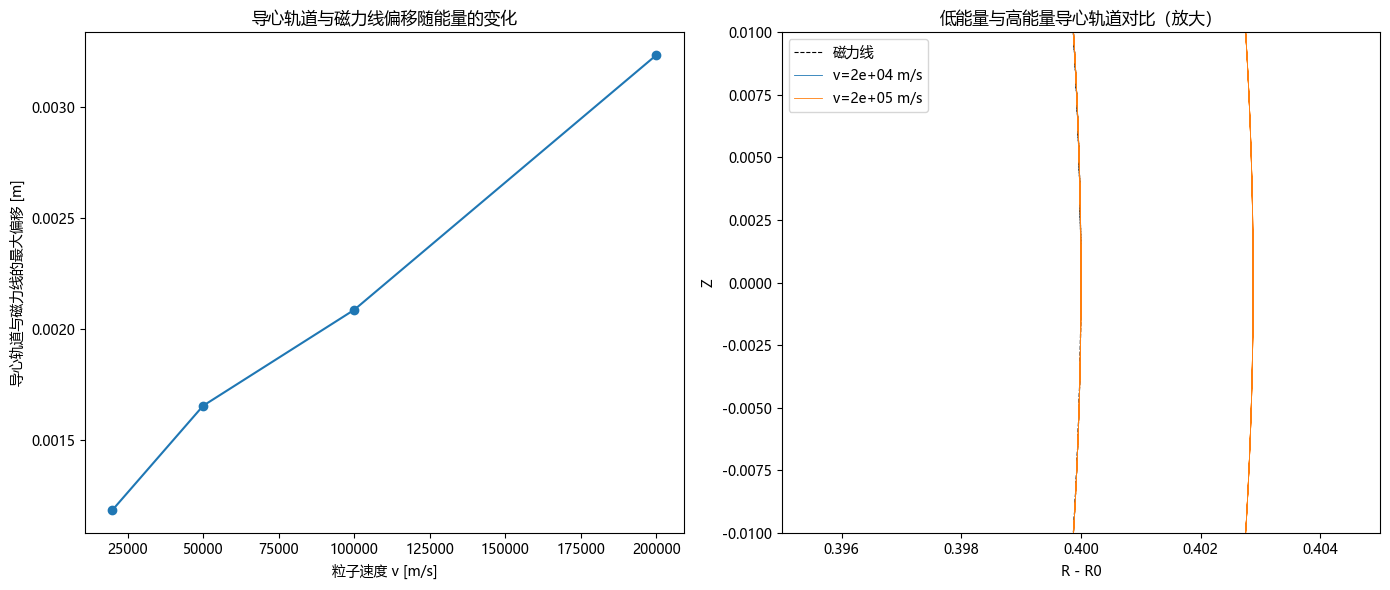

In [4]:
# 固定 pitch angle = 0.1，改变能量
ratio = 0.1
energies = [2e4, 5e4, 1e5, 2e5]
labels = ['2×10⁴ m/s', '5×10⁴ m/s', '1×10⁵ m/s', '2×10⁵ m/s']

# 先画一条参考磁力线
x0 = np.array([10.4, 0.0, 0.0])
fieldline = integrate_fieldline(field, x0, 1e-3, 100000)
R_fl = np.sqrt(fieldline[:, 0]**2 + fieldline[:, 1]**2)
Z_fl = fieldline[:, 2]

# 降采样用于距离计算
R_fl_ds = R_fl[::100]
Z_fl_ds = Z_fl[::100]

deviations = []
for v_total in energies:
    v_para = ratio * v_total
    v_perp = np.sqrt(v_total**2 - v_para**2)
    v = np.array([v_perp, v_para, 0.0])
    p = Particle(PROTON_CHARGE, PROTON_MASS, np.array([10.4, 0.0, 0.0]), v)
    result = guiding_center_integrate(field, p, dt=1e-7, n_steps=150000)
    R = np.sqrt(result['trajectory'][:, 0]**2 + result['trajectory'][:, 1]**2)
    Z = result['trajectory'][:, 2]
    
    R_ds = R[::100]
    Z_ds = Z[::100]
    min_dists = []
    for i in range(len(R_ds)):
        dists = np.sqrt((R_fl_ds - R_ds[i])**2 + (Z_fl_ds - Z_ds[i])**2)
        min_dists.append(np.min(dists))
    deviations.append(np.max(min_dists))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 偏移随能量的变化
axes[0].plot(energies, deviations, 'o-', lw=1.5)
axes[0].set_xlabel('粒子速度 v [m/s]')
axes[0].set_ylabel('导心轨道与磁力线的最大偏移 [m]')
axes[0].set_title('导心轨道与磁力线偏移随能量的变化')

# 低能量与高能量导心轨道对比（放大到 mm 量级）
for i, v_total in enumerate([2e4, 2e5]):
    v_para = ratio * v_total
    v_perp = np.sqrt(v_total**2 - v_para**2)
    v = np.array([v_perp, v_para, 0.0])
    p = Particle(PROTON_CHARGE, PROTON_MASS, np.array([10.4, 0.0, 0.0]), v)
    result = guiding_center_integrate(field, p, dt=1e-7, n_steps=150000)
    R = np.sqrt(result['trajectory'][:, 0]**2 + result['trajectory'][:, 1]**2)
    Z = result['trajectory'][:, 2]
    axes[1].plot(R_fl - R0, Z_fl, 'k--', lw=0.8, label='磁力线' if i == 0 else None)
    axes[1].plot(R - R0, Z, lw=0.6, label=f'v={v_total:.0e} m/s')

axes[1].set_xlabel('R - R0')
axes[1].set_ylabel('Z')
axes[1].set_title('低能量与高能量导心轨道对比（放大）')
axes[1].set_xlim(0.395, 0.405)
axes[1].set_ylim(-0.01, 0.01)
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. 轨道特征的物理解释

### 5.1 为什么会有 passing 与 trapped 之分？

托卡马克中磁场强度随位置变化：环内侧磁场强，环外侧磁场弱。当粒子沿磁力线向强场区运动时，磁矩守恒使垂直速度增大、平行速度减小。若初始平行速度太小，粒子会在某处平行速度降为零并被反射，形成 trapped 轨道；若平行速度足够大，粒子可以越过强场区继续沿磁力线运动，形成 passing 轨道。

**捕获判据推导**：磁矩 $\mu = v_\perp^2/(2B)$ 守恒。设粒子在外侧中平面（$B = B_{min}$）的平行速度占比为 $\xi = v_\parallel/v$。当粒子运动到反射点（$v_\parallel = 0$）时，垂直速度满足 $v_\perp^2 = v^2$，对应磁场 $B_t = B_{min}/(1-\xi^2)$。粒子被捕获要求反射点磁场不超过轨道上的最大磁场 $B_{max}$，即 $B_t \le B_{max}$，从而得到：
$$\xi^2 \le 1 - \frac{B_{min}}{B_{max}}$$

因此捕获判据为：
$$\frac{v_\parallel^2}{v^2} < 1 - \frac{B_{min}}{B_{max}} \quad \Rightarrow \quad \text{trapped}$$

对本项目 $r = 0.4$ m 磁面，$B_{min} = 4.81$ T，$B_{max} = 5.21$ T，临界 pitch $\xi_c = \sqrt{1 - B_{min}/B_{max}} \approx 0.277$。

### 5.2 为什么香蕉轨道是香蕉形？

Trapped 粒子在磁镜点之间来回弹跳，同时受到 $\nabla B$ 漂移和曲率漂移的影响。这些漂移使导心在径向发生偏移，且偏移方向随粒子在环内侧/外侧的位置变化。在 R-Z 平面上，粒子轨迹形成一个闭合的弯曲曲线，形状像香蕉，因此称为香蕉轨道。

### 5.3 为什么能量高会偏离磁力线？

拉莫尔半径 $\rho_L = m v_\perp / (qB)$ 随能量增加而增大。导心近似要求 $\rho_L$ 远小于磁场变化尺度（如 $R_0$ 或 $a$）。当能量较高时，$\rho_L$ 与装置尺度可比，导心轨道与磁力线的偏移显著，漂移效应（$\nabla B$、曲率）也更加突出。

### 5.4 导心近似与全粒子轨道的关系

导心近似忽略了粒子的快速回旋，只保留缓慢漂移。当 $\rho_* = \rho_L/R_0 \ll 1$ 时，导心近似与全粒子轨道高度一致；当 $\rho_*$ 较大时，导心近似误差增大，全粒子轨道与磁力线的偏移更加明显。

## 6. 总结

本汇报完成了以下工作：
1. 推导了带电粒子运动方程的无量纲形式，明确了关键参数 $\rho_*$ 的物理意义。
2. 画出了托卡马克磁力线及其极向面投影，并叠加了磁面。
3. 通过改变 pitch angle，展示了 passing 到 trapped 轨道的转变。
4. 通过改变粒子能量，展示了轨道与磁力线偏移的增大趋势。
5. 从磁矩守恒、磁镜反射、漂移运动等角度解释了轨道特征的成因。

这些结果为后续研究真实平衡位形、电场效应和碰撞输运打下了基础。